# 3 · Validación temporal

<a href="https://colab.research.google.com/github/B3njjaman/MLOps-en-Azure/blob/main/modulos/modulo-1/03_validacion_temporal.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"></a>

**Módulo 1 · Del notebook al código reproducible.** La lección 1 terminó con una promesa rota: el notebook prometía un error de 6,1 MWh y la planta entregó 9,0 en 2026. Una de las causas es la partición al azar, que mira el futuro. Esta lección corrige esa falla, la 5.2 de la lección 1, y cumple la condición 2 de la Definición 1.6: evaluar el modelo como se va a usar.

La lección define qué es un esquema de validación, cuándo respeta el tiempo y cuánto futuro deja ver, y lo mide con la planta: cada esquema promete un error, y 2026 dice cuál prometió bien. Demuestra una propiedad del proceso AR(1) que explica por qué interpolar es más fácil que pronosticar, y la contrasta con lo que realmente aprovecha el bosque. Después separa la validación, donde se elige, de la prueba, donde se mira una sola vez, y cierra con la separación entre entrenamiento y prueba, que aquí no hace falta y en otros problemas sí.

Requisitos: numpy, pandas, scikit-learn y matplotlib, que Colab y Kaggle ya traen. La primera celda descarga el simulador de la planta si no está junto al notebook. Todo corre en CPU, en pocos minutos. Las cifras del texto salen de scikit-learn 1.9 y pandas 3.1. Con otras versiones, como las de Colab, algunas cambian en el último decimal (la lección 2 explica por qué).

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

if not Path("planta.py").exists():  # en Colab o Kaggle; en el PC ya está junto al notebook
    urlretrieve(
        "https://raw.githubusercontent.com/B3njjaman/MLOps-en-Azure/main/modulos/modulo-1/planta.py",
        "planta.py",
    )

from importlib.metadata import version

for paquete in ("numpy", "pandas", "scikit-learn", "matplotlib"):
    print(paquete, version(paquete))

numpy 2.4.6
pandas 3.1.0
scikit-learn 1.9.1
matplotlib 3.11.2


## 1. Lo que prometió la partición al azar

La lección 1 comparó dos formas de partir los días. Con la partición al azar, el modelo prometió un MAE de 6,10 MWh; con la temporal, que entrena hasta 2024 y prueba 2025, el MAE fue 8,12. La razón es la Propiedad 1.1: el error de prueba estima el riesgo solo si los días de prueba se parecen a los días de uso y son independientes del entrenamiento. Los días de uso son futuros, y la partición al azar entrena con días posteriores a los de prueba.

Desde esta lección el modelo usa el **pronóstico de temperatura**, que es el dato que existe a las 06:00 (la lección 4 explica por qué con detalle). Con ese cambio, el modelo entrenado con toda la historia entrega en 2026 un MAE de 8,50, la cifra de la sección 5.3 de la lección 1. Ese es el **error real**: lo que cualquier método de evaluación debería haber prometido.

Las features se calculan sobre la serie completa de `generar()`, para que los rezagos de enero de 2026 usen diciembre de 2025.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, TimeSeriesSplit
from planta import generar

TURQUESA, VIOLETA, AMBAR, ROSA, GRIS = "#0d9488", "#7c3aed", "#d97706", "#e11d48", "#57606a"

serie = generar()  # 2022 a 2026: la misma simulación que historia() y futuro()

X = pd.DataFrame(
    {
        "dia_semana": serie["fecha"].dt.day_of_week,
        "produccion": serie["produccion"],
        "temperatura_pronostico": serie["temperatura_pronostico"],
        "consumo_ayer": serie["consumo"].shift(1),
        "consumo_semana_pasada": serie["consumo"].shift(7),
    }
)
X, y, fechas = X.iloc[7:], serie["consumo"].iloc[7:], serie["fecha"].iloc[7:]  # sin los primeros 7 días

es_2026 = (fechas >= "2026-01-01").to_numpy()
X_h, y_h, f_h = X[~es_2026], y[~es_2026], fechas[~es_2026]  # la historia, 2022 a 2025
n = len(X_h)


def nuevo_modelo(n_arboles=200, **hiperparametros):
    return RandomForestRegressor(n_estimators=n_arboles, random_state=0, n_jobs=-1, **hiperparametros)


modelo = nuevo_modelo().fit(X_h, y_h)
error_real = mean_absolute_error(y[es_2026], modelo.predict(X[es_2026]))
print(f"Días de historia: {n}")
print(f"Error real: MAE en 2026, entrenado con toda la historia: {error_real:.2f} MWh")

Días de historia: 1454
Error real: MAE en 2026, entrenado con toda la historia: 8.50 MWh


## 2. Esquemas de validación

Los días se numeran $t = 1, \dots, n$ en orden. Una evaluación puede entrenar y medir varias veces, con distintas partes de la historia. Conviene darle nombre a esa estructura.

**Definición 3.1 (esquema de validación).** Un esquema de validación es una lista de pares $(E_1, P_1), \dots, (E_K, P_K)$ de conjuntos de días, con $E_k \cap P_k = \varnothing$ para cada $k$. El conjunto $E_k$ es el entrenamiento del pliegue $k$ (*fold*) y $P_k$ es su prueba.

**Definición 3.2 (respeta el tiempo).** Un esquema respeta el tiempo si en cada pliegue el entrenamiento es anterior a la prueba: $\max E_k < \min P_k$ para todo $k$.

**Definición 3.3 (error del esquema).** Sea $f_k$ el modelo entrenado con los días $E_k$ y sea $\widehat R_k = \widehat R_{P_k}(f_k)$ su error de prueba, como en la Definición 1.5. El error del esquema es el promedio de los pliegues:

$$\widehat R = \frac{1}{K} \sum_{k=1}^{K} \widehat R_k.$$

**Definición 3.4 (fuga).** La fuga de un esquema es la fracción de días de prueba que tienen algún día de entrenamiento posterior:

$$\text{fuga} = \frac{\sum_k \big\lvert \{\, t \in P_k : \exists\, e \in E_k,\ e > t \,\} \big\rvert}{\sum_k \lvert P_k \rvert}.$$

Mide cuánto del futuro ve el modelo al evaluarse. No dice cuánto lo aprovecha: eso depende del modelo.

**Propiedad 3.1.** Un esquema respeta el tiempo si y solo si su fuga es 0.

*Demostración.* La fuga es 0 si y solo si ningún $t \in P_k$ tiene un $e \in E_k$ con $e > t$, es decir, si y solo si $\max E_k < t$ para todo $t \in P_k$ y todo $k$. Eso es $\max E_k < \min P_k$ para todo $k$. $\square$

**Definición 3.5 (cuatro esquemas).** Con $n$ días:

- **Aleatorio.** Los días se reparten al azar en $K$ grupos del mismo tamaño. En el pliegue $k$, $P_k$ es el grupo $k$ y $E_k$ son los demás. En scikit-learn, `KFold(n_splits=K, shuffle=True, random_state=0)`.
- **Holdout temporal** con corte $c$. Un solo pliegue: $E = \{1, \dots, c\}$ y $P = \{c+1, \dots, n\}$.
- **Origen móvil con ventana creciente**, con $K$ pliegues, prueba de $h$ días y separación $g$. Las pruebas son los últimos $Kh$ días, en bloques consecutivos de $h$: $P_k = \{n - (K-k+1)h + 1, \dots, n - (K-k)h\}$, y el entrenamiento llega hasta $g$ días antes de la prueba: $E_k = \{1, \dots, \min P_k - g - 1\}$. En scikit-learn, `TimeSeriesSplit(n_splits=K, test_size=h, gap=g)`.
- **Ventana deslizante** de $w$ días. Lo mismo, pero $E_k$ conserva solo los últimos $w$ días: $E_k = \{\min P_k - g - w, \dots, \min P_k - g - 1\}$. Se agrega `max_train_size=w`.

**Definición 3.6 (separación).** La separación $g$ es el número de días que se descartan entre el último día de entrenamiento y el primero de prueba.

El diagrama muestra los pliegues del origen móvil sobre 14 días: primero con ventana creciente, después con ventana deslizante, y al final con $g = 1$.

<img src="https://b3njjaman.github.io/MLOps-en-Azure/imagenes/diagramas/modulo-1/origen-movil.svg" alt="Catorce días seguidos en dos bloques de cuatro pliegues cada uno. En el bloque de ventana creciente, el pliegue 1 entrena con los días 1 a 6 y prueba con el 7 y el 8; el pliegue 2 entrena con los días 1 a 8 y prueba con el 9 y el 10; el pliegue 3 prueba con el 11 y el 12 y el pliegue 4 con el 13 y el 14, y en cada uno el entrenamiento crece. En el bloque de ventana deslizante, el entrenamiento conserva solo los últimos 4 días antes de cada prueba. En el último paso, con separación g = 1, el último día de entrenamiento de cada pliegue de la ventana creciente queda descartado. En todos los pliegues el entrenamiento es anterior a la prueba" width="760">

Un esquema es una lista de índices, y el resto del código se escribe una sola vez para cualquiera de ellos. Los índices son posiciones en la tabla, así que los primeros días son $0, 1, 2, \dots$ y no $1, 2, 3, \dots$: solo cambia el origen de la numeración.

In [3]:
def evaluar(esquema, X, y, n_arboles=200, **hiperparametros):
    # MAE de cada pliegue: entrena con E_k y mide en P_k
    maes = []
    for E, P in esquema:
        m = nuevo_modelo(n_arboles, **hiperparametros).fit(X.iloc[E], y.iloc[E])
        maes.append(mean_absolute_error(y.iloc[P], m.predict(X.iloc[P])))
    return np.array(maes)


def fuga(esquema):
    # fracción de días de prueba con algún día de entrenamiento posterior (Definición 3.4)
    con_fuga = sum((P < E.max()).sum() for E, P in esquema)
    return con_fuga / sum(len(P) for E, P in esquema)


def respeta_el_tiempo(esquema):
    return all(E.max() < P.min() for E, P in esquema)


corte = int((f_h < "2025-01-01").sum())  # el holdout entrena hasta 2024 y prueba 2025

esquemas = {
    "aleatorio, K=5": list(KFold(5, shuffle=True, random_state=0).split(X_h)),
    "holdout temporal, 2025": [(np.arange(corte), np.arange(corte, n))],
    "origen móvil, K=3, h=365": list(TimeSeriesSplit(3, test_size=365).split(X_h)),
    "origen móvil, K=12, h=30": list(TimeSeriesSplit(12, test_size=30).split(X_h)),
    "origen móvil, K=12, h=30, g=7": list(TimeSeriesSplit(12, test_size=30, gap=7).split(X_h)),
    "ventana deslizante, K=12, h=30, w=365": list(
        TimeSeriesSplit(12, test_size=30, max_train_size=365).split(X_h)
    ),
}

for nombre, esquema in esquemas.items():
    print(f"{nombre:40s} pliegues {len(esquema):2d}   fuga {fuga(esquema):.3f}   respeta el tiempo: {respeta_el_tiempo(esquema)}")

aleatorio, K=5                           pliegues  5   fuga 0.999   respeta el tiempo: False
holdout temporal, 2025                   pliegues  1   fuga 0.000   respeta el tiempo: True
origen móvil, K=3, h=365                 pliegues  3   fuga 0.000   respeta el tiempo: True
origen móvil, K=12, h=30                 pliegues 12   fuga 0.000   respeta el tiempo: True
origen móvil, K=12, h=30, g=7            pliegues 12   fuga 0.000   respeta el tiempo: True
ventana deslizante, K=12, h=30, w=365    pliegues 12   fuga 0.000   respeta el tiempo: True



La fuga ya se puede calcular sin entrenar nada. La aleatoria tiene fuga 0,999: casi todo día de prueba tiene algún día de entrenamiento posterior. Los demás esquemas respetan el tiempo y su fuga es 0, como dice la Propiedad 3.1. El Ejercicio 1 demuestra que la fuga de la aleatoria tiende a 1 cuando $n$ crece.


## 3. Por qué interpolar es más fácil que pronosticar

Lo que el modelo no sabe de un día es el término $u_t$ de la Definición 1.3, el AR(1) con coeficiente 0,6. Pronosticar el día $t$ con el pasado y *rellenar* el día $t$ con sus dos vecinos son problemas distintos. La partición al azar convierte el primero en el segundo, y el segundo es más fácil.

**Propiedad 3.2 (interpolar frente a pronosticar).** Sea $u_t = \phi\,u_{t-1} + \varepsilon_t$ un proceso AR(1) estacionario, con $\lvert\phi\rvert < 1$ y $\varepsilon_t \sim N(0, \sigma_\varepsilon^2)$ independientes. Entonces:

1. $u_t \mid u_{t-1} \sim N\big(\phi\,u_{t-1},\ \sigma_\varepsilon^2\big)$.
2. $u_t \mid u_{t-1}, u_{t+1} \sim N\!\left(\dfrac{\phi\,(u_{t-1} + u_{t+1})}{1 + \phi^2},\ \dfrac{\sigma_\varepsilon^2}{1 + \phi^2}\right)$.

Por lo tanto, la desviación estándar del error del mejor predictor que usa los dos vecinos es $1/\sqrt{1 + \phi^2}$ veces la del mejor predictor que usa solo el pasado.

*Demostración.* La parte 1 es la definición del proceso. Para la parte 2, sean $a = u_{t-1}$ y $b = u_{t+1}$. El proceso es markoviano: $u_{t+1}$ depende del pasado solo a través de $u_t$. Por la regla de Bayes,

$$p(u_t \mid a, b) = \frac{p(b \mid u_t, a)\, p(u_t \mid a)}{p(b \mid a)} = \frac{p(b \mid u_t)\, p(u_t \mid a)}{p(b \mid a)} \ \propto\ \exp\!\left(-\frac{(u_t - \phi a)^2 + (b - \phi u_t)^2}{2\sigma_\varepsilon^2}\right),$$

donde el denominador no depende de $u_t$. Al expandir el exponente,

$$(u_t - \phi a)^2 + (b - \phi u_t)^2 = (1 + \phi^2)\,u_t^2 - 2\phi\,(a + b)\,u_t + \text{const} = (1 + \phi^2)\left(u_t - \frac{\phi\,(a + b)}{1 + \phi^2}\right)^2 + \text{const}.$$

Es el exponente de una normal con media $\phi(a + b)/(1 + \phi^2)$ y varianza $\sigma_\varepsilon^2/(1 + \phi^2)$. Como la media condicional minimiza el error cuadrático, la desviación estándar del error óptimo es la raíz de la varianza condicional. $\square$

Con $\phi = 0{,}6$, el factor es $1/\sqrt{1{,}36} \approx 0{,}857$: con los dos vecinos, el término $u_t$ se predice con un error 14 % menor. Como $\mathbb{E}\lvert N(0, s^2)\rvert = s\sqrt{2/\pi}$, el MAE de un error normal cambia en la misma proporción. La propiedad se puede comprobar con un AR(1) simulado y con el $u_t$ de la planta, que se recupera de la tabla restando a $y_t$ todo lo demás de la Definición 1.3.

In [4]:
def minimos_cuadrados(objetivo, *predictoras):
    A = np.column_stack(predictoras)
    coef, *_ = np.linalg.lstsq(A, objetivo, rcond=None)
    return coef, (objetivo - A @ coef).std()


def comparar(u, nombre):
    anterior, actual, siguiente = u[:-2], u[1:-1], u[2:]
    c1, s1 = minimos_cuadrados(actual, anterior)
    c2, s2 = minimos_cuadrados(actual, anterior, siguiente)
    print(f"{nombre}")
    print(f"  solo el pasado:      coeficiente {c1[0]:.3f}, desviación del error {s1:.3f}")
    print(f"  con los dos vecinos: coeficientes {c2[0]:.3f} y {c2[1]:.3f}, desviación del error {s2:.3f}")
    print(f"  razón de desviaciones: {s2 / s1:.3f}")


phi, sigma = 0.6, 5.0
rng = np.random.default_rng(0)
ruido = rng.normal(0, sigma, 200_000)
u_sim = np.empty(len(ruido))
u_sim[0] = ruido[0] / np.sqrt(1 - phi**2)
for t in range(1, len(ruido)):
    u_sim[t] = phi * u_sim[t - 1] + ruido[t]

comparar(u_sim, "AR(1) simulado, 200000 días")

tau = serie["temperatura"]
dias = (serie["fecha"] - pd.Timestamp("2022-01-01")).dt.days
resto = 60 + 0.07 * serie["produccion"] + 4 * np.maximum(tau - 16, 0) + 3 * np.maximum(10 - tau, 0) + 0.02 * dias
comparar((serie["consumo"] - resto).to_numpy(), f"u_t de la planta, {len(serie)} días")

print(f"\nValor teórico: coeficientes {phi:.3f} y {phi / (1 + phi**2):.3f}; razón {1 / np.sqrt(1 + phi**2):.3f}")

AR(1) simulado, 200000 días
  solo el pasado:      coeficiente 0.598, desviación del error 5.006
  con los dos vecinos: coeficientes 0.440 y 0.440, desviación del error 4.299
  razón de desviaciones: 0.859
u_t de la planta, 1826 días
  solo el pasado:      coeficiente 0.606, desviación del error 4.911
  con los dos vecinos: coeficientes 0.439 y 0.439, desviación del error 4.223
  razón de desviaciones: 0.860

Valor teórico: coeficientes 0.600 y 0.441; razón 0.857



La simulación reproduce la propiedad: la razón de desviaciones es 0,859 (teórica, 0,857) y los coeficientes con los dos vecinos son iguales entre sí, 0,440, cerca de $\phi/(1 + \phi^2) = 0{,}441$. En la planta, el $u_t$ recuperado de la tabla da casi lo mismo: razón 0,860 y coeficientes 0,439.

La diferencia con la teoría es error de muestreo. Con $n \approx 1826$ días, el error estándar del coeficiente estimado es $\sqrt{(1 - \phi^2)/n} \approx 0{,}019$, y el 0,606 de la planta está a 0,3 errores estándar del 0,600. Con 200 mil días ese error baja a 0,002. El redondeo de $y_t$ y $\tau_t$ a un decimal pesa mucho menos.

La propiedad dice cuánto *podría* ganar un modelo que use los vecinos. Falta ver cuánto gana el bosque del notebook, que no está hecho para interpolar. Eso se mide en la sección 4.1.


## 4. Medir los esquemas con la planta

Cada esquema promete un error, y ya se conoce el error real de 2026. Hay que recordar que ese error real es **una sola realización**: 365 días autocorrelacionados de una simulación con una semilla. Otra semilla daría otro número, y las comparaciones con él son aproximadas.

La tabla calcula $\widehat R$ para cada esquema con el modelo de la sección 1, y agrega el error estándar entre pliegues, $s/\sqrt{K}$. Es una medida de cuánto varía el error de un pliegue a otro, y es aproximada porque los entrenamientos de los pliegues se solapan. No mide el sesgo de un esquema. Con un solo pliegue no hay error estándar.

In [5]:
filas = []
pliegues = {}
for nombre, esquema in esquemas.items():
    r = evaluar(esquema, X_h, y_h)
    pliegues[nombre] = r
    filas.append(
        {
            "esquema": nombre,
            "pliegues": len(esquema),
            "MAE estimado": r.mean(),
            "error estándar": r.std(ddof=1) / np.sqrt(len(r)) if len(r) > 1 else np.nan,
            "fuga": fuga(esquema),
        }
    )

tabla = pd.DataFrame(filas).set_index("esquema")
tabla["menos el error real"] = tabla["MAE estimado"] - error_real
print(f"Error real en 2026: {error_real:.2f} MWh")
tabla.round(3)

Error real en 2026: 8.50 MWh


,pliegues,MAE estimado,error estándar,fuga,menos el error real
esquema,,,,,
"aleatorio, K=5",5,6.422,0.115,0.999,-2.082
"holdout temporal, 2025",1,8.008,NaN,0.000,-0.496
"origen móvil, K=3, h=365",3,7.528,0.240,0.000,-0.977
"origen móvil, K=12, h=30",12,7.367,0.557,0.000,-1.138
"origen móvil, K=12, h=30, g=7",12,7.467,0.553,0.000,-1.038
"ventana deslizante, K=12, h=30, w=365",12,6.769,0.579,0.000,-1.736



El error real de 2026 es 8,50, una sola realización, como se dijo antes. Tres lecturas:

- **La aleatoria promete 6,42**, 2,08 MWh menos que el error real. Su error estándar entre pliegues es 0,12, el más bajo de la tabla. Eso no la hace más confiable: los pliegues aleatorios son intercambiables, todos mezclan los mismos años, y por eso varían poco entre sí. El error estándar mide esa variación, no el sesgo que causa la fuga.
- **Los esquemas que respetan el tiempo prometen entre 6,77 y 8,01.** El holdout de 2025 es el más cercano, con 8,01. El origen móvil con $K = 12$ da 7,37, con error estándar 0,56, y queda a poco más de dos errores estándar del real. Como el real es una sola realización y los errores estándar son aproximados, esa distancia no es un número exacto. Respetar el tiempo quita la fuga, pero no todo el sesgo: 2026 es un año nuevo, con la planta en un nivel más alto, y todo esquema temporal mide con años anteriores.
- **La separación pesa poco aquí.** Con $g = 7$ el error es 7,47 frente a 7,37 con $g = 0$. Los dos esquemas tienen los mismos pliegues de prueba, así que el error estándar entre pliegues (0,56) no sirve para compararlos: hay que mirar la diferencia por pliegue, que se calcula abajo.

La ventana deslizante de 365 días promete 6,77, la cifra más baja entre las temporales. No es una falla del esquema: mide una política de entrenamiento distinta, que olvida los años viejos. El Ejercicio 3 la compara con 2026.


In [6]:
# los dos esquemas tienen los mismos días de prueba, así que la comparación correcta es pareada
dif = pliegues["origen móvil, K=12, h=30, g=7"] - pliegues["origen móvil, K=12, h=30"]
print(f"g=7 menos g=0, pareado por pliegue: {dif.mean():+.2f} ± {dif.std(ddof=1) / np.sqrt(len(dif)):.2f} MWh")

g=7 menos g=0, pareado por pliegue: +0.10 ± 0.04 MWh



Con $g = 7$ el error sube unos 0,1 MWh de forma consistente: la diferencia pareada es +0,10 con error estándar 0,04. El efecto es pequeño, y es lo esperable cuando el entrenamiento pierde una semana de datos y el pronóstico es de un día.


Los pliegues, dibujados al estilo de la figura de validación cruzada de scikit-learn, muestran de dónde viene la fuga: en el esquema aleatorio, los días de prueba (ámbar) están repartidos en toda la historia, y el entrenamiento (turquesa) tiene días de los dos lados.

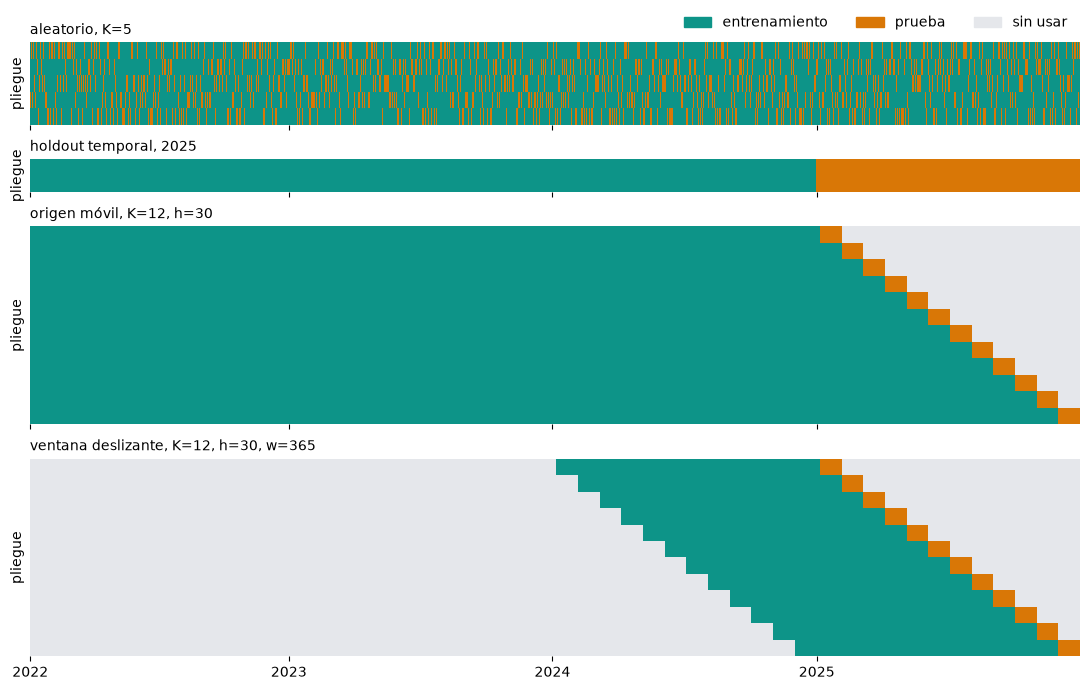

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

anio = f_h.dt.year.to_numpy()
inicios = np.flatnonzero(np.diff(anio, prepend=anio[0] - 1) != 0)  # primer día de cada año
mapa_de_colores = ListedColormap(["#e5e7eb", TURQUESA, AMBAR])


def mapa(esquema):
    m = np.zeros((len(esquema), n))
    for k, (E, P) in enumerate(esquema):
        m[k, E], m[k, P] = 1, 2
    return m


mostrar = ["aleatorio, K=5", "holdout temporal, 2025", "origen móvil, K=12, h=30", "ventana deslizante, K=12, h=30, w=365"]
fig, ejes = plt.subplots(len(mostrar), 1, figsize=(11, 7), sharex=True, height_ratios=[5, 2, 12, 12])
for ax, nombre in zip(ejes, mostrar):
    ax.imshow(mapa(esquemas[nombre]), cmap=mapa_de_colores, vmin=0, vmax=2, aspect="auto", interpolation="nearest")
    ax.set_title(nombre, loc="left", fontsize=10)
    ax.set_ylabel("pliegue")
    ax.set_yticks([])
    ax.spines[:].set_visible(False)
ejes[-1].set_xticks(inicios, [str(a) for a in anio[inicios]])
ejes[0].legend(
    handles=[Patch(color=TURQUESA, label="entrenamiento"), Patch(color=AMBAR, label="prueba"), Patch(color="#e5e7eb", label="sin usar")],
    ncols=3, frameon=False, loc="lower right", bbox_to_anchor=(1, 1),
)
plt.tight_layout()
plt.show()

Y el gráfico de lo que promete cada esquema, con el error real de 2026 como línea de referencia. Las barras de error son un error estándar.

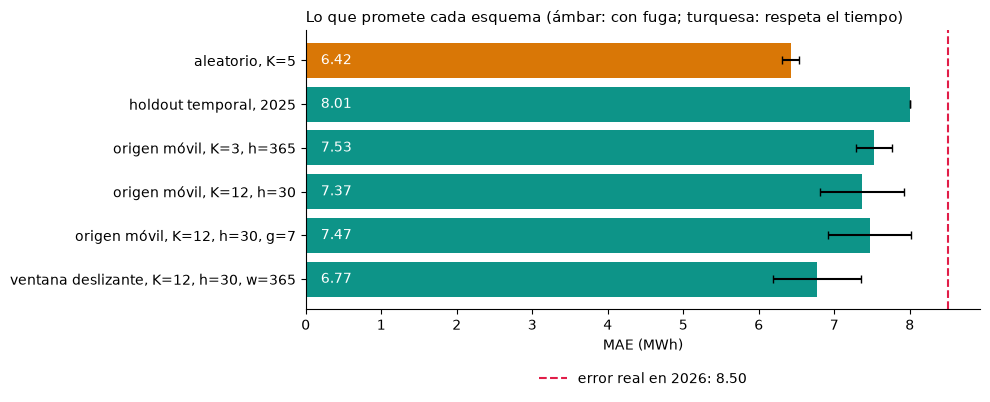

In [8]:
orden = tabla.index[::-1]
colores = [AMBAR if tabla.loc[e, "fuga"] > 0 else TURQUESA for e in orden]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(orden, tabla.loc[orden, "MAE estimado"], xerr=tabla.loc[orden, "error estándar"].fillna(0), color=colores, capsize=3)
ax.axvline(error_real, color=ROSA, ls="--", lw=1.5, label=f"error real en 2026: {error_real:.2f}")
for i, e in enumerate(orden):
    ax.text(0.2, i, f"{tabla.loc[e, 'MAE estimado']:.2f}", va="center", color="white", fontsize=10)
ax.set_xlabel("MAE (MWh)")
ax.set_title("Lo que promete cada esquema (ámbar: con fuga; turquesa: respeta el tiempo)", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncols=1)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 4.1 De dónde sale la diferencia

La aleatoria promete poco y la fuga dice que ve el futuro. Quedan dos preguntas: cuánto de esa diferencia viene de los vecinos inmediatos, la Propiedad 3.2, y cuánto de ver días posteriores en general.

**Vecinos.** Se prueba con un día de cada 20, y se mide en 5 particiones que difieren en el día de partida. En una fila de entrenamiento, el consumo del día de prueba $t$ aparece como feature en dos filas: la del día $t+1$ (`consumo_ayer`) y la del día $t+7$ (`consumo_semana_pasada`). El experimento descarta del entrenamiento esas filas junto con la del día $t-1$, y después también $t-7$. Si el bosque aprovechara a los vecinos, el error subiría al descartarlos. La diferencia con el caso base se mide por partición, y su error estándar sale de las 5 diferencias.

In [9]:
def mae_sin_filas(descartar, desfases=range(0, 20, 4)):
    errores = []
    for d in desfases:
        P = np.arange(d, n, 20)  # un día de cada 20
        fuera = np.setdiff1d(np.unique(np.clip(descartar(P), 0, n - 1)), P)
        E = np.setdiff1d(np.arange(n), np.concatenate([fuera, P]))
        m = nuevo_modelo().fit(X_h.iloc[E], y_h.iloc[E])
        errores.append(mean_absolute_error(y_h.iloc[P], m.predict(X_h.iloc[P])))
    return np.array(errores)


casos = {
    "todos los demás días": lambda P: P,
    "sin t-1, t+1 y t+7": lambda P: np.concatenate([P - 1, P + 1, P + 7]),
    "sin t±1 y t±7": lambda P: np.concatenate([P - 1, P + 1, P - 7, P + 7]),
}
base = mae_sin_filas(casos["todos los demás días"])
print(f"{'todos los demás días':24s} MAE {base.mean():.2f}")
for nombre in list(casos)[1:]:
    r = mae_sin_filas(casos[nombre])
    d = r - base
    print(f"{nombre:24s} MAE {r.mean():.2f}   diferencia {d.mean():+.2f} ± {d.std(ddof=1) / np.sqrt(len(d)):.2f}")

todos los demás días     MAE 6.48


sin t-1, t+1 y t+7       MAE 6.56   diferencia +0.08 ± 0.06


sin t±1 y t±7            MAE 6.62   diferencia +0.15 ± 0.04



Descartar las filas que contienen el consumo del día de prueba sube el error en 0,08 MWh, con un error estándar de 0,06, y descartar además las de $t \pm 7$ lo sube en 0,15, con 0,04. Frente a los 0,95 MWh que separan a la aleatoria (6,42) del origen móvil con $K = 12$ (7,37), los vecinos explican como mucho cerca de 0,15, es decir, alrededor de una sexta parte. La cifra es una cota de lo que aprovecha el bosque: descartar también las filas $t \pm 7$ le quita más datos de entrenamiento, y parte de la subida puede ser solo eso.

La lección 1 señaló a los vecinos como la causa; medido, pesan poco con este modelo. El bosque recibe cinco features de un solo día y no recibe el consumo del día siguiente como entrada, así que no tiene cómo interpolar. La Propiedad 3.2 es el techo de lo que podría ganar un modelo que sí los use, por ejemplo un suavizador o uno con el índice del día como feature.


**El futuro.** Se prueba con 2024 y se entrena con tres conjuntos de días: el pasado (2022 y 2023), el futuro (2025) y los dos. Del futuro se quita la primera semana de 2025, porque sus features (`consumo_ayer`, `consumo_semana_pasada`) traen consumos de fines de 2024, que son días de prueba.

In [10]:
anio_h = f_h.dt.year.to_numpy()
prueba_2024 = anio_h == 2024
borde = (anio_h == 2025) & (f_h.dt.day_of_year.to_numpy() <= 7)  # filas con consumos de 2024 como features
conjuntos = {
    "solo el pasado (2022 y 2023)": anio_h < 2024,
    "solo el futuro (2025)": (anio_h == 2025) & ~borde,
    "el pasado y el futuro": (anio_h != 2024) & ~borde,
}
for nombre, E in conjuntos.items():
    m = nuevo_modelo().fit(X_h[E], y_h[E])
    print(f"{nombre:30s} {E.sum():4d} días de entrenamiento   MAE en 2024: {mean_absolute_error(y_h[prueba_2024], m.predict(X_h[prueba_2024])):.2f}")

solo el pasado (2022 y 2023)    723 días de entrenamiento   MAE en 2024: 7.26


solo el futuro (2025)           358 días de entrenamiento   MAE en 2024: 6.92


el pasado y el futuro          1081 días de entrenamiento   MAE en 2024: 6.33



La comparación limpia es la del pasado con el futuro: "solo el futuro" gana (6,92 contra 7,26) con la mitad de los días de entrenamiento (358 contra 723). Para el nivel de la planta alrededor de 2024, un año al otro lado informa más que dos años del lado de atrás. "El pasado y el futuro" baja a 6,33, pero ahí también hay más datos (1081 días), así que esa mejora mezcla el efecto del futuro con el de entrenar con más. Estos días no son vecinos de 2024 día a día: lo que ayuda es conocer el nivel de la planta alrededor de los días de prueba. Entre esto y los vecinos está la explicación de la diferencia entre la aleatoria y el origen móvil: los vecinos, poco, y ver días posteriores, la mayor parte, aunque con estos datos no se separa del todo de entrenar con más días. En producción el modelo solo tiene el pasado, y el esquema tiene que medir eso.


## 5. Validación y prueba

Un esquema que respeta el tiempo sirve para dos cosas distintas, y mezclarlas es otra forma de mirar el futuro.

**Definición 3.7 (validación y prueba).** Los días de **validación** son los que se usan para decidir: hiperparámetros, features, umbrales. Se pueden mirar tantas veces como haga falta. Los días de **prueba** son los que solo se miran una vez, al final, para estimar el riesgo del modelo elegido. Los días de prueba deben ser posteriores a los de validación.

La lección 1 mostró en su Ejercicio 3 que elegir con los días de prueba equivale a entrenar con ellos: el mínimo de varios errores de prueba es optimista. Aquí se hace bien. Se eligen los hiperparámetros del bosque con origen móvil dentro de 2022 a 2024 (4 pliegues de 90 días); se usa 2025 como prueba, con el modelo elegido y entrenado con 2022 a 2024; y se compara con 2026, entrenando con toda la historia. En rigor, 2025 ya apareció en la sección 4, como holdout y como pliegues del origen móvil, pero solo para comparar esquemas: ninguna decisión sobre el modelo se tomó con esas cifras.

Para que corra rápido, la rejilla usa bosques de 100 árboles. El modelo final, el de la prueba y el del uso, tiene 200, como en las secciones 1 y 4.

In [11]:
import itertools

dev = anio_h <= 2024  # 2022 a 2024: aquí se elige
X_dev, y_dev = X_h[dev], y_h[dev]
validacion = list(TimeSeriesSplit(4, test_size=90).split(X_dev))

filas = []
for profundidad, hoja in itertools.product([6, 10, None], [1, 3, 6]):
    r = evaluar(validacion, X_dev, y_dev, 100, max_depth=profundidad, min_samples_leaf=hoja)
    filas.append({"max_depth": profundidad, "min_samples_leaf": hoja, "MAE de validación": r.mean(), "error estándar": r.std(ddof=1) / 2})

rejilla = pd.DataFrame(filas).sort_values("MAE de validación").reset_index(drop=True)
rejilla.round(2)

,max_depth,min_samples_leaf,MAE de validación,error estándar
0,NaN,1,6.68,0.49
1,NaN,3,6.69,0.51
2,10.0,3,6.69,0.49
3,10.0,1,6.73,0.47
4,NaN,6,6.78,0.61
5,10.0,6,6.79,0.60
6,6.0,1,6.88,0.49
7,6.0,3,6.90,0.50
8,6.0,6,6.99,0.60


In [12]:
elegido = rejilla.iloc[0]
hiperparametros = {
    "max_depth": None if pd.isna(elegido["max_depth"]) else int(elegido["max_depth"]),
    "min_samples_leaf": int(elegido["min_samples_leaf"]),
}
print("Elegido con la validación:", hiperparametros)

# La prueba: 2025, con el modelo final (200 árboles) entrenado solo con 2022 a 2024
es_2025 = anio_h == 2025
m = nuevo_modelo(**hiperparametros).fit(X_dev, y_dev)
mae_prueba = mean_absolute_error(y_h[es_2025], m.predict(X_h[es_2025]))

# El uso: 2026, con el modelo final entrenado con toda la historia
m = nuevo_modelo(**hiperparametros).fit(X_h, y_h)
mae_uso = mean_absolute_error(y[es_2026], m.predict(X[es_2026]))

print(f"Validación (2022 a 2024, origen móvil, 100 árboles): MAE {elegido['MAE de validación']:.2f}")
print(f"Prueba (2025):                                       MAE {mae_prueba:.2f}")
print(f"Uso (2026):                                          MAE {mae_uso:.2f}")

Elegido con la validación: {'max_depth': None, 'min_samples_leaf': 1}


Validación (2022 a 2024, origen móvil, 100 árboles): MAE 6.68
Prueba (2025):                                       MAE 8.01
Uso (2026):                                          MAE 8.50



La rejilla no tiene un ganador claro: los cuatro primeros candidatos están entre 6,68 y 6,73, con errores estándar de cerca de 0,5. Elegir entre ellos es elegir ruido, y el primero coincide con los valores por defecto del bosque. Esto confirma por qué conviene una rejilla corta y un criterio simple. Lo que importa de la sección es el orden de los tres números:

- **La validación (6,68) sirve para ordenar candidatos, no para prometer.** Sus pliegues son de 2024, con menos historia y una planta más baja que en 2025.
- **La prueba (8,01) es la promesa.** Con 2025 no se decidió nada, y es posterior a la validación. Coincide con el holdout de la sección 4 porque el modelo elegido tiene los valores por defecto.
- **El uso (8,50) la confirma con un margen de 0,49.** Es el error real de las secciones 1 y 4. Ese margen es el cambio de año, que ningún esquema con datos de 2025 hacia atrás puede ver.

Si 2025 se hubiera usado para elegir, el 8,01 ya no sería una prueba: sería otra validación, y la promesa honesta tendría que esperar a 2026.


## 6. Cuándo hace falta la separación

La separación $g$ de la Definición 3.6 pesó poco en la tabla de la sección 4: el esquema con $g = 7$ sube el error unos 0,1 MWh respecto del de $g = 0$. Con un pronóstico de un día, el entrenamiento de un pliegue puede llegar hasta el día anterior a la prueba, porque a las 06:00 del primer día de prueba ya se conoce el consumo de ayer. Hace falta $g > 0$ cuando eso no es cierto, por dos razones:

- **El objetivo cubre varios días.** Si lo que se pronostica es el consumo medio de los próximos $w$ días, la etiqueta de un día de entrenamiento incluye días posteriores a él. En producción, esa etiqueta no se conoce hasta $w - 1$ días después.
- **El horizonte es de $H$ días.** Si el modelo del día $p$ solo puede usar datos hasta el día $p - H$, la etiqueta del día $p - H + 1$ ya no se conoce al entrenar.

**Observación 3.1 (cuánta separación).** Con horizonte $H$ y un objetivo que promedia $w$ días hacia adelante, el entrenamiento de un pliegue no puede incluir días $s$ cuya etiqueta termine después del último dato disponible. Eso exige $g \ge H + w - 2$. Con $H = 1$ y $w = 1$ (el caso de la planta) es $g \ge 0$.

Un ejemplo con $w = 7$. Se pronostica el consumo medio de los días $t$ a $t + 6$, con el plan de producción medio de esos mismos días (el plan se conoce de antemano) y el consumo medio de los 7 días anteriores. Se agrega el día del año, una feature de calendario muy común, y después se repite el experimento sin ella. El esquema es de origen móvil con 20 pliegues de 7 días, con $g = 0$ y con $g = 6$. Como los dos esquemas tienen los mismos días de prueba, se compara pliegue a pliegue.

In [13]:
c = serie["consumo"]
adelante = pd.api.indexers.FixedForwardWindowIndexer(window_size=7)

Z = pd.DataFrame(
    {
        "dia_semana": serie["fecha"].dt.day_of_week,
        "dia_anio": serie["fecha"].dt.day_of_year,
        "produccion_media_7": serie["produccion"].rolling(adelante, min_periods=7).mean(),  # plan de t a t+6
        "consumo_medio_previo_7": c.shift(1).rolling(7).mean(),  # consumo de t-7 a t-1
    }
)
z = c.rolling(adelante, min_periods=7).mean()  # el objetivo: consumo medio de t a t+6
valido = Z.notna().all(axis=1) & z.notna()
Z, z, fz = Z[valido], z[valido], serie.loc[valido, "fecha"]

entrenable = (fz <= "2025-12-25").to_numpy()  # la etiqueta del 25 de diciembre usa hasta el 31
Z_h, z_h = Z[entrenable], z[entrenable]
uso = (fz >= "2026-01-01").to_numpy()

for nombre, columnas in {"con dia_anio": list(Z.columns), "sin dia_anio": [c for c in Z.columns if c != "dia_anio"]}.items():
    real_7 = mean_absolute_error(z[uso], nuevo_modelo(100).fit(Z_h[columnas], z_h).predict(Z.loc[uso, columnas]))
    r = {g: evaluar(list(TimeSeriesSplit(20, test_size=7, gap=g).split(Z_h)), Z_h[columnas], z_h, 100) for g in (0, 6)}
    ee = {g: r[g].std(ddof=1) / np.sqrt(20) for g in r}
    dif = r[6] - r[0]
    print(f"{nombre}: g=0 {r[0].mean():.2f} ± {ee[0]:.2f}   g=6 {r[6].mean():.2f} ± {ee[6]:.2f}   "
          f"g=6 menos g=0 (pareado) {dif.mean():+.2f} ± {dif.std(ddof=1) / np.sqrt(20):.2f}   error real 2026 {real_7:.2f}")

con dia_anio: g=0 8.75 ± 1.16   g=6 9.28 ± 1.20   g=6 menos g=0 (pareado) +0.53 ± 0.28   error real 2026 10.14


sin dia_anio: g=0 8.25 ± 1.10   g=6 8.12 ± 1.14   g=6 menos g=0 (pareado) -0.13 ± 0.21   error real 2026 9.86



Con la feature `dia_anio`, $g = 0$ promete 8,75 MWh y $g = 6$, 9,28, con errores estándar de cerca de 1,2 por esquema. La diferencia pareada es +0,53 ± 0,28. Sin esa feature, la diferencia desaparece: -0,13 ± 0,21, con 8,25 y 8,12.

Esto es consistente con la fuga de etiquetas, pero no la prueba. Con $g = 0$, la última etiqueta de entrenamiento comparte 6 de sus 7 días con la primera de prueba, y un bosque que tiene el día del año puede ubicar los días cercanos y aprovechar esa cercanía. Sin esa feature, no tiene cómo ubicarlos. Es una explicación plausible, no probada: un mecanismo así predeciría un efecto que baja de a poco con $g$, y el Ejercicio 4 muestra un salto casi completo con $g = 2$. Con 20 pliegues, además, la incertidumbre es del mismo tamaño que el efecto.

La conclusión práctica no depende del mecanismo: si el objetivo cubre varios días, la separación de la Observación 3.1 es la que garantiza que no hay etiquetas compartidas, y cuesta poco. En la planta, con horizonte de un día y objetivo de un día, no hace falta.


## 7. La simulación

La [simulación de esta lección](https://b3njjaman.github.io/MLOps-en-Azure/complementarios/validacion.html) deja elegir entre los cuatro esquemas de esta lección y mover $K$, $h$, $g$ y la ventana $w$ sobre la historia de la planta. Sirve para ver cómo cambian los pliegues, la fuga y el error estimado frente al error real de 2026. Los bosques ya están entrenados para cada combinación, así que no hay que esperar a que corran.

## 8. En Azure

El backtest de esta lección es el paso que decide si un modelo nuevo puede reemplazar al vigente. En Azure Machine Learning se escribe como un *component* del pipeline de entrenamiento, y una compuerta lo sigue. Es un adelanto del módulo 3, donde se construye el pipeline completo.

| En el notebook | En Azure Machine Learning |
|---|---|
| `evaluar(esquema, X, y)` y `fuga(esquema)` | Un *command component* `backtest` que corre el mismo código desde `src/` |
| $K$, $h$ y $g$ | Las entradas del component, con un valor por defecto |
| La tabla de $\widehat R_k$ | Un reporte (la salida del component) y las métricas registradas con MLflow en el job |
| «Si no le gana al modelo vigente y a la línea base, no se usa» | Un segundo component, la compuerta, que falla y detiene el pipeline |

El component declara sus entradas y su salida, igual que cualquier command component:

```yaml
# components/backtest.yml
$schema: https://azuremlschemas.azureedge.net/latest/commandComponent.schema.json
name: backtest_pronostico
version: 1
type: command
inputs:
  features:
    type: uri_folder
  pliegues:
    type: integer
    default: 12
  prueba_dias:
    type: integer
    default: 30
  separacion:
    type: integer
    default: 0
outputs:
  reporte:
    type: uri_folder
code: ../src
environment: azureml:forecast-env:1   # el environment de la lección 2, con versión fija
command: >-
  python backtest.py --features ${{inputs.features}} --pliegues ${{inputs.pliegues}}
  --prueba-dias ${{inputs.prueba_dias}} --separacion ${{inputs.separacion}}
  --reporte ${{outputs.reporte}}
```

En el pipeline, el backtest va después de las features y antes de la compuerta, que lee su reporte:

```yaml
# pipelines/entrenamiento-consumo.yml (fragmento)
jobs:
  backtest:                                   # origen móvil, sin separación (horizonte de 1 día)
    type: command
    component: ../components/backtest.yml
    inputs:
      features: ${{parent.jobs.features.outputs.tabla}}
      pliegues: 12
      prueba_dias: 30
  compuerta:                                  # contra el modelo en producción y la línea base
    type: command
    component: ../components/compuerta.yml
    inputs:
      reporte: ${{parent.jobs.backtest.outputs.reporte}}
```

La compuerta es código de Python que termina con un error si el candidato no cumple. Si un paso falla, los pasos que dependen de su salida no corren. El registro del modelo va después de la compuerta, así que el modelo no se registra:

```python
# src/compuerta.py (esquema)
import json
import sys
from pathlib import Path

reporte = json.loads(Path(sys.argv[1], "reporte.json").read_text())
if not (reporte["mae_candidato"] < reporte["mae_campeon"] and reporte["mae_candidato"] < reporte["mae_linea_base"]):
    sys.exit("El candidato no le gana al modelo en producción y a la línea base en el backtest.")
```

Para que la comparación sea justa, el candidato y el modelo vigente se evalúan con el mismo esquema y los mismos pliegues. Como el artefacto del modelo vigente ya vio parte de esos pliegues, lo que se compara es su receta (el código y los hiperparámetros), reentrenada en cada pliegue con los mismos días de entrenamiento que el candidato. La otra salida es comparar solo en días posteriores a la fecha de corte de su entrenamiento. Una compuerta real, además, exige un margen: reemplaza al vigente si el candidato lo mejora por más que el ruido del backtest, y no con un `<` estricto como el del esquema de arriba. Y el esquema de la compuerta es el de esta lección: respeta el tiempo, con la separación que pida el horizonte. Un backtest con partición al azar dejaría pasar modelos que fallan en producción.

## Ejercicios

**Ejercicio 1 (la fuga de la aleatoria).** Sea $P_k$ un grupo de $m$ días elegido al azar, de $n$ días en total, con $m < n$. Demostrar que, en el pliegue $k$ de un esquema aleatorio, la fuga esperada cumple $\mathbb{E}[\text{fuga}_k] \ge 1 - \dfrac{1}{n - m}$, y que por lo tanto tiende a 1 cuando $n$ crece con $K$ fijo. Comprobarlo con `KFold`.

*Pista:* un día de prueba **no** tiene fuga solo si todos los días posteriores a él también son de prueba. ¿Cuántos días cumplen eso?

<details>
<summary>Solución</summary>

Un día $t \in P_k$ no tiene fuga si y solo si los días $t, t+1, \dots, n$ están todos en $P_k$. Esos días forman un bloque final de $P_k$ de largo $L$: el mayor $j$ tal que los últimos $j$ días de la serie son de prueba. Entonces la fuga del pliegue es $1 - L/m$.

Como $P_k$ es un subconjunto de tamaño $m$ elegido al azar, la probabilidad de que los últimos $j$ días estén en $P_k$ es

$$\mathbb{P}(L \ge j) = \prod_{i=0}^{j-1} \frac{m - i}{n - i} \le \left(\frac{m}{n}\right)^j,$$

porque $\frac{m-i}{n-i} \le \frac{m}{n}$ cuando $m \le n$. Entonces

$$\mathbb{E}[L] = \sum_{j \ge 1} \mathbb{P}(L \ge j) \le \sum_{j \ge 1} \left(\frac{m}{n}\right)^j = \frac{m}{n - m},$$

y $\mathbb{E}[\text{fuga}_k] = 1 - \mathbb{E}[L]/m \ge 1 - \frac{1}{n - m}$. Con $K$ fijo, $m \approx n/K$ y $n - m \to \infty$, así que la cota tiende a 1. $\square$

```python
import numpy as np
from sklearn.model_selection import KFold

K = 5
for n_dias in (50, 500, 5000):
    medidas = []
    for semilla in range(2000):
        esquema = list(KFold(K, shuffle=True, random_state=semilla).split(np.arange(n_dias)))
        medidas.append(sum((P < E.max()).sum() for E, P in esquema) / n_dias)
    m = n_dias / K
    cota = 1 - 1 / (n_dias - m)
    print(f"n = {n_dias:5d}   fuga media {np.mean(medidas):.5f}   cota {cota:.5f}")
```


Con 2000 particiones por tamaño y $K = 5$, la fuga media coincide con la cota, que es casi exacta: 0,97541 con 50 días (cota 0,97500), 0,99756 con 500 (0,99750) y 0,99975 con 5000 (0,99975). Con los 1454 días de la planta, la fuga de la tabla es 0,999.


</details>

**Ejercicio 2 (cuántos pliegues).** Con pruebas de $h = 30$ días, calcular el error estimado del origen móvil con $K = 1, 2, 3, 6, 12$ y $24$ pliegues, con su error estándar. ¿Desde qué $K$ se estabiliza la estimación? ¿Qué se gana y qué se pierde al agregar pliegues?

*Pista:* en `TimeSeriesSplit`, el último pliegue es siempre el mismo. Con $K$ pliegues se usan los últimos $K$ de los 24. Basta entrenar 24 veces.

<details>
<summary>Solución</summary>

```python
r24 = evaluar(list(TimeSeriesSplit(24, test_size=30).split(X_h)), X_h, y_h)
for K in (1, 2, 3, 6, 12, 24):
    r = r24[-K:]  # con K pliegues se usan los últimos K: el resto no cambia
    ee = r.std(ddof=1) / np.sqrt(K) if K > 1 else float("nan")
    print(f"K = {K:2d}   MAE estimado {r.mean():.2f}   error estándar {ee:.2f}")
```


Con $K = 1$ el error es 12,09: es solo diciembre de 2025, un mes con error alto, y no dice nada del resto. La media baja a 9,35, 9,14 y 7,63 con 2, 3 y 6 pliegues, a 7,37 con 12 y a 6,98 con 24. Lo que cambia con $K$ es la variación entre pliegues: el error estándar baja de 2,74 a 0,34, y la desviación entre pliegues, de 3,9 a 1,7. La media, en cambio, sigue bajando. Agregar pliegues antiguos agrega períodos con menos entrenamiento y otro nivel de la planta, y eso mueve la media; no hay un $K$ donde la estimación quede fija.

Con $h = 30$, $K = 12$ es el primer valor que cubre un año completo, con todas las estaciones y las dos paradas, y es un punto de partida razonable. Cada pliegue extra cuesta un entrenamiento.


</details>

**Ejercicio 3 (ventana creciente o deslizante).** La planta sube su consumo 0,02 MWh por día, y el bosque no extrapola. Calcular el error del backtest con ventana creciente y con ventanas deslizantes de 730 y 365 días, y el error real de 2026 del modelo que se entrenaría con esa misma ventana. ¿Qué esquema conviene?

*Pista:* un backtest debe copiar la política de entrenamiento de producción. ¿Qué política se está evaluando en cada caso?

<details>
<summary>Solución</summary>

```python
for w in (None, 730, 365):
    esquema = list(TimeSeriesSplit(12, test_size=30, max_train_size=w).split(X_h))
    estimado = evaluar(esquema, X_h, y_h).mean()
    ultimos = slice(-w, None) if w else slice(None)  # el modelo de producción usa la misma ventana
    m = nuevo_modelo().fit(X_h.iloc[ultimos], y_h.iloc[ultimos])
    real = mean_absolute_error(y[es_2026], m.predict(X[es_2026]))
    print(f"w = {str(w):5s}   backtest {estimado:.2f}   error real en 2026 {real:.2f}")
```


El backtest y 2026 ordenan igual las tres políticas: cuanto más corta la ventana, menor el error estimado y menor el error real. La brecha entre el backtest y 2026 es casi la misma en las tres, cerca de 1,1 MWh. Entrenar con los últimos 365 días da 7,86 en 2026, contra 8,50 con toda la historia.

Esa mejora se debe en buena parte al sesgo del modelo, no a una propiedad de los datos: el bosque no extrapola la tendencia, y una ventana corta hace que sus datos de entrenamiento queden más cerca del nivel actual de la planta. Un modelo que sí siguiera la tendencia, como el del Ejercicio 4 de la lección 1, no tendría por qué preferir la ventana corta.

Ningún esquema es mejor en abstracto. El backtest debe copiar la política con la que se va a entrenar en producción: si cada mes se reentrena con toda la historia, ventana creciente; si se reentrena con el último año, ventana deslizante de 365 días. Y como el backtest ordena bien las políticas, sirve también para elegir entre ellas.


</details>

**Ejercicio 4 (separación que sí importa).** En el ejemplo de la sección 6, medir el error estimado con $g = 0, 2, 4, 6, 8$. ¿A partir de qué $g$ se estabiliza? Comparar con la Observación 3.1.

*Pista:* con $H = 1$ y $w = 7$, la observación pide $g \ge 6$.

<details>
<summary>Solución</summary>

```python
for g in (0, 2, 4, 6, 8):
    esquema = list(TimeSeriesSplit(20, test_size=7, gap=g).split(Z_h))
    print(f"g = {g}:  MAE estimado {evaluar(esquema, Z_h, z_h, 100).mean():.2f}")
```


Entre $g = 0$ y $g = 2$ el error pasa de 8,75 a 9,22, y de ahí en adelante se queda entre 9,22 y 9,38, sin tendencia clara y con diferencias dentro del ruido (cerca de 1,2 de error estándar por esquema). Un salto casi completo con $g = 2$ no encaja con una fuga que se debilite de a poco con la distancia, así que el mecanismo de la sección 6 sigue siendo una hipótesis. Lo que sí es seguro es la regla: la Observación 3.1 pide $g \ge 6$ porque es el valor que garantiza que ninguna etiqueta de entrenamiento comparta un día con la prueba.


</details>

**Siguiente:** la lección 4 construye las features con una sola transformación, guardada junto al modelo y calculada con los datos de las 06:00. Es la falla 5.3 de la lección 1, el *training-serving skew*: el modelo de esta lección ya usa el pronóstico de temperatura, y la lección 4 explica por qué tiene que hacerlo.